In [0]:
import pandas as pd
import numpy as np

In [0]:
procedure = spark.table("analystlab.default.procedures").toPandas()

display(procedure)


START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
2011-01-02T09:26:36.000Z,2011-01-02T12:58:36.000Z,3de74169-7f67-9304-91d4-757e0f3a14d2,32c84703-2481-49cd-d571-3899d5820253,265764009,Renal dialysis (procedure),903,null,null
2011-01-03T05:44:39.000Z,2011-01-03T06:01:42.000Z,d9ec2e44-32e9-9148-179a-1653348cc4e2,c98059da-320a-c0a6-fced-c8815f3e3f39,76601001,Intramuscular injection,2477,null,null
2011-01-04T14:49:55.000Z,2011-01-04T15:04:55.000Z,d856d6e6-4c98-e7a2-129b-44076c63d008,2cfd4ddd-ad13-fe1e-528b-15051cea2ec3,703423002,Combined chemotherapy and radiation therapy (procedure),11620,3.63406005E8,Malignant tumor of colon
2011-01-05T04:02:09.000Z,2011-01-05T04:17:09.000Z,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,17966936-0878-f4db-128b-a43ae10d0878,173160006,Diagnostic fiberoptic bronchoscopy (procedure),9796,1.62573006E8,Suspected lung cancer (situation)
2011-01-05T12:58:36.000Z,2011-01-05T16:42:36.000Z,3de74169-7f67-9304-91d4-757e0f3a14d2,9de5f0b0-4ba4-ce6f-45fb-b55c202f31a5,265764009,Renal dialysis (procedure),1255,null,null
2011-01-06T18:12:41.000Z,2011-01-06T18:17:12.000Z,712e95dd-f313-39c7-1fc9-8463c15c105f,44057ea7-178f-c3c3-965a-78e4521fa43b,410006001,Digital examination of rectum,564,null,null
2011-01-07T21:02:09.000Z,2011-01-07T22:39:45.000Z,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,4b6a38e6-7df9-2d75-d850-6bd662f3d05b,698354004,Magnetic resonance imaging for measurement of brain volume (procedure),5050,4.24132E8,Non-small cell carcinoma of lung TNM stage 1 (disorder)
2011-01-07T22:39:45.000Z,2011-01-07T23:00:45.000Z,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,cc36dc26-6019-94a5-93b7-7bbf312e6fc4,703423002,Combined chemotherapy and radiation therapy (procedure),15760,4.24132E8,Non-small cell carcinoma of lung TNM stage 1 (disorder)
2011-01-08T16:42:36.000Z,2011-01-08T20:15:36.000Z,3de74169-7f67-9304-91d4-757e0f3a14d2,03f54837-bfc8-81aa-4905-f74ceb35162f,265764009,Renal dialysis (procedure),1556,null,null
2011-01-09T16:11:28.000Z,2011-01-09T16:51:19.000Z,f4cde0dc-db22-5d98-5228-55121ae74cad,17d162fa-fc25-b3c5-5e72-20287a55eaf1,73761001,Colonoscopy,13620,null,null


%m%

## 1. Research Question and Objectives

### 1.1 Research Question

Do procedure costs differ substantially across frequently performed procedures?

### 1.2 Relevance of the Research Question

Healthcare procedures differ in their nature, complexity and resource requirements. These differences may contribute to variations in recorded procedure costs.

Investigating cost differences across frequently performed procedures can help identify procedures with higher recorded costs and provide insight into variations in healthcare expenditure.

The analysis also examines whether procedure duration is associated with recorded procedure costs, providing an additional perspective on factors that may be related to procedure expenditure.

### 1.3 Research Objectives

The objectives of this investigation are:

1. To identify the most frequently performed procedures in the dataset.
2. To examine the distribution of recorded procedure costs.
3. To investigate procedure durations and identify potential outliers.
4. To compare cost distributions across the five most frequently performed procedures.
5. To investigate whether procedure duration is associated with procedure cost.
6. To interpret the findings and provide recommendations while considering the limitations of the dataset.

**Conduct Exploratory Data Analysis (EDA)**

In [0]:
 # Check the number of rows and columns
procedure.shape

(47701, 9)

In [0]:
 # Display the first five records
procedure.head()

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
0,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,32c84703-2481-49cd-d571-3899d5820253,265764009,Renal dialysis (procedure),903,NaN,None
1,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,c98059da-320a-c0a6-fced-c8815f3e3f39,76601001,Intramuscular injection,2477,NaN,None
2,2011-01-04 14:49:55,2011-01-04 15:04:55,d856d6e6-4c98-e7a2-129b-44076c63d008,2cfd4ddd-ad13-fe1e-528b-15051cea2ec3,703423002,Combined chemotherapy and radiation therapy (p...,11620,363406005.0,Malignant tumor of colon
3,2011-01-05 04:02:09,2011-01-05 04:17:09,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,17966936-0878-f4db-128b-a43ae10d0878,173160006,Diagnostic fiberoptic bronchoscopy (procedure),9796,162573006.0,Suspected lung cancer (situation)
4,2011-01-05 12:58:36,2011-01-05 16:42:36,3de74169-7f67-9304-91d4-757e0f3a14d2,9de5f0b0-4ba4-ce6f-45fb-b55c202f31a5,265764009,Renal dialysis (procedure),1255,NaN,None


In [0]:
 # Display all column names
procedure.columns

Index(['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION',
       'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION'],
      dtype='object')

In [0]:
 # Check data types and non-null values
procedure.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47701 entries, 0 to 47700
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   START              47701 non-null  datetime64[ns]
 1   STOP               47701 non-null  datetime64[ns]
 2   PATIENT            47701 non-null  object        
 3   ENCOUNTER          47701 non-null  object        
 4   CODE               47701 non-null  int64         
 5   DESCRIPTION        47701 non-null  object        
 6   BASE_COST          47701 non-null  int64         
 7   REASONCODE         10756 non-null  float64       
 8   REASONDESCRIPTION  10756 non-null  object        
dtypes: datetime64[ns](2), float64(1), int64(2), object(4)
memory usage: 3.3+ MB


In [0]:
 # Generate summary statistics
procedure.describe(include="all")

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
count,47701,47701,47701,47701,4.770100e+04,47701,47701.000000,1.075600e+04,10756
unique,NaN,NaN,793,14670,NaN,163,NaN,NaN,46
top,NaN,NaN,1712d26d-822d-1e3a-2267-0a9dba31d7c8,66b2ab44-a2cc-8053-8f4e-c5be57e50cc4,NaN,Assessment of health and social care needs (pr...,NaN,NaN,Normal pregnancy
freq,NaN,NaN,1783,186,NaN,4596,NaN,NaN,5718
mean,2016-09-21 09:59:37.091989760,2016-09-21 10:32:52.887088384,NaN,NaN,1.098683e+14,NaN,2212.064967,3.342532e+11,NaN
min,2011-01-02 09:26:36,2011-01-02 12:58:36,NaN,NaN,1.225002e+06,NaN,1.000000,5.602001e+06,NaN
25%,2014-02-21 14:21:19,2014-02-21 15:08:51,NaN,NaN,2.251580e+08,NaN,431.000000,7.289200e+07,NaN
50%,2016-07-20 16:58:48,2016-07-20 17:13:48,NaN,NaN,4.153000e+08,NaN,431.000000,7.289200e+07,NaN
75%,2019-04-30 11:20:27,2019-04-30 11:51:34,NaN,NaN,7.629930e+08,NaN,966.000000,7.289200e+07,NaN
max,2022-01-29 20:35:37,2022-01-29 21:08:12,NaN,NaN,1.633503e+16,NaN,289531.000000,6.781100e+13,NaN


In [0]:
 # Task 2 – Point 2: Check missing values

missing_values = procedure.isnull().sum()

missing_percentage = (
    procedure.isnull().sum() / len(procedure)
) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_summary

,Missing Values,Missing Percentage
START,0,0.000000
STOP,0,0.000000
PATIENT,0,0.000000
ENCOUNTER,0,0.000000
CODE,0,0.000000
DESCRIPTION,0,0.000000
BASE_COST,0,0.000000
REASONCODE,36945,77.451206
REASONDESCRIPTION,36945,77.451206


In [0]:
 # Task 2 – Point 2: Check missing-value alignment

pd.crosstab(
    procedure["REASONCODE"].isnull(),
    procedure["REASONDESCRIPTION"].isnull()
)

REASONDESCRIPTION,False,True
REASONCODE,,
False,10756,0
True,0,36945


In [0]:
 # Task 2 – Point 2: Check duplicate records

print("Number of duplicate rows:", procedure.duplicated().sum())

Number of duplicate rows: 0


In [0]:
 # Task 2 – Point 2: Check procedure date consistency

invalid_dates = procedure[procedure["STOP"] < procedure["START"]]

print("Records with STOP before START:", len(invalid_dates))

Records with STOP before START: 0


In [0]:
 # Task 2 – Point 2: Calculate procedure duration

procedure["DURATION_HOURS"] = (
    procedure["STOP"] - procedure["START"]
).dt.total_seconds() / 3600

# View descriptive statistics
procedure["DURATION_HOURS"].describe()

count    47701.000000
mean         0.554388
std          1.923217
min          0.000000
25%          0.250000
50%          0.275556
75%          0.493056
max        384.000000
Name: DURATION_HOURS, dtype: float64

In [0]:
 # Task 2 – Point 2: Investigate unusually long procedures

longest_procedures = procedure.sort_values(
    by="DURATION_HOURS",
    ascending=False
)

longest_procedures[
    ["START", "STOP", "DESCRIPTION", "DURATION_HOURS"]
].head(10)

,START,STOP,DESCRIPTION,DURATION_HOURS
25825,2017-01-11 09:03:19,2017-01-27 09:03:19,Admission to long stay hospital,384.000000
9720,2013-10-22 02:32:09,2013-10-23 20:32:09,Human epidermal growth factor receptor 2 gene ...,42.000000
13905,2014-06-04 04:33:43,2014-06-05 19:33:43,Human epidermal growth factor receptor 2 gene ...,39.000000
32350,2018-07-19 02:25:40,2018-07-20 13:25:40,Human epidermal growth factor receptor 2 gene ...,35.000000
29167,2017-09-30 15:52:26,2017-10-01 21:52:26,Human epidermal growth factor receptor 2 gene ...,30.000000
36065,2019-05-24 08:29:16,2019-05-25 12:29:16,Human epidermal growth factor receptor 2 gene ...,28.000000
24880,2016-10-25 07:14:06,2016-10-26 09:14:06,Human epidermal growth factor receptor 2 gene ...,26.000000
34804,2019-02-14 03:05:07,2019-02-15 04:05:07,Human epidermal growth factor receptor 2 gene ...,25.000000
34749,2019-02-10 16:44:33,2019-02-10 22:33:33,Prostatectomy,5.816667
13040,2014-04-03 08:19:23,2014-04-03 13:48:23,Prostatectomy,5.483333


In [0]:
 # Task 2 – Point 2: Detect duration outliers using IQR

Q1 = procedure["DURATION_HOURS"].quantile(0.25)
Q3 = procedure["DURATION_HOURS"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

duration_outliers = procedure[
    (procedure["DURATION_HOURS"] < lower_limit) |
    (procedure["DURATION_HOURS"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(duration_outliers))

Q1: 0.25
Q3: 0.4930555555555556
IQR: 0.24305555555555558
Lower limit: -0.11458333333333337
Upper limit: 0.857638888888889
Number of potential outliers: 5133


In [0]:
 # Task 2 – Point 2: Examine procedure costs

procedure["BASE_COST"].describe()

count     47701.000000
mean       2212.064967
std        5572.978748
min           1.000000
25%         431.000000
50%         431.000000
75%         966.000000
max      289531.000000
Name: BASE_COST, dtype: float64

In [0]:
 # Task 2 – Point 2: Detect cost outliers using IQR

Q1_cost = procedure["BASE_COST"].quantile(0.25)
Q3_cost = procedure["BASE_COST"].quantile(0.75)

IQR_cost = Q3_cost - Q1_cost

lower_cost = Q1_cost - (1.5 * IQR_cost)
upper_cost = Q3_cost + (1.5 * IQR_cost)

cost_outliers = procedure[
    (procedure["BASE_COST"] < lower_cost) |
    (procedure["BASE_COST"] > upper_cost)
]

print("Q1:", Q1_cost)
print("Q3:", Q3_cost)
print("IQR:", IQR_cost)
print("Lower limit:", lower_cost)
print("Upper limit:", upper_cost)
print("Number of potential cost outliers:", len(cost_outliers))

Q1: 431.0
Q3: 966.0
IQR: 535.0
Lower limit: -371.5
Upper limit: 1768.5
Number of potential cost outliers: 9174


An investigation of the ten highest-cost procedures revealed that ICU admissions accounted for the five most expensive records, with the highest recorded cost being 289,531. Coronary artery bypass grafting also appeared frequently among the highest-cost procedures, followed by electrical cardioversion. Interestingly, the ICU admission records had a recorded duration of only 0.5 hours. This suggests that recorded procedure duration does not necessarily reflect the total resources or costs associated with a procedure. The high-cost observations should be investigated further rather than automatically treated as data errors.

In [0]:
 # Task 2 – Point 2: Investigate the highest procedure costs

most_expensive = procedure.sort_values(
    by="BASE_COST",
    ascending=False
)

most_expensive[
    ["DESCRIPTION", "BASE_COST", "DURATION_HOURS"]
].head(10)

,DESCRIPTION,BASE_COST,DURATION_HOURS
41089,Admit to ICU (procedure),289531,0.50
41161,Admit to ICU (procedure),236283,0.50
40035,Admit to ICU (procedure),199610,0.50
40131,Admit to ICU (procedure),193251,0.50
41269,Admit to ICU (procedure),112627,0.50
37398,Coronary artery bypass grafting,67168,0.25
18655,Coronary artery bypass grafting,65744,0.25
30619,Coronary artery bypass grafting,58755,0.25
26098,Coronary artery bypass grafting,56169,0.25
39780,Electrical cardioversion,44532,0.25


Pearson correlation analysis was conducted to investigate the relationship between BASE_COST and DURATION_HOURS. The correlation coefficient was -0.0118, indicating a negligible negative linear relationship between procedure cost and recorded duration. This suggests that longer recorded procedure durations are not necessarily associated with higher procedure costs. The result also indicates that other factors, such as procedure type, may be more relevant to differences in procedure costs. Correlation alone does not establish causation.

In [0]:
 # Task 2 – Point 3: Correlation between cost and duration

correlation = procedure[
    ["BASE_COST", "DURATION_HOURS"]
].corr()

print(correlation)

                BASE_COST  DURATION_HOURS
BASE_COST        1.000000       -0.011817
DURATION_HOURS  -0.011817        1.000000


In [0]:
 # Task 2 – Point 3: Average cost by procedure type

procedure_cost_summary = (
    procedure.groupby("DESCRIPTION")["BASE_COST"]
    .agg(["count", "mean", "median"])
    .sort_values(by="mean", ascending=False)
)

procedure_cost_summary.head(10)

,count,mean,median
DESCRIPTION,,,
Admit to ICU (procedure),5,206260.400000,199610.0
Coronary artery bypass grafting,9,47085.888889,43374.0
Lumpectomy of breast (procedure),5,29353.000000,29349.0
Hemodialysis (procedure),27,29299.555556,28314.0
Insertion of biventricular implantable cardioverter defibrillator,4,27201.000000,25503.0
Electrical cardioversion,1383,25903.110629,25066.0
Partial resection of colon,7,25229.285714,23031.0
Fine needle aspiration biopsy of lung (procedure),1,23141.000000,23141.0
Percutaneous mechanical thrombectomy of portal vein using fluoroscopic guidance,57,20228.035088,19073.0


Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


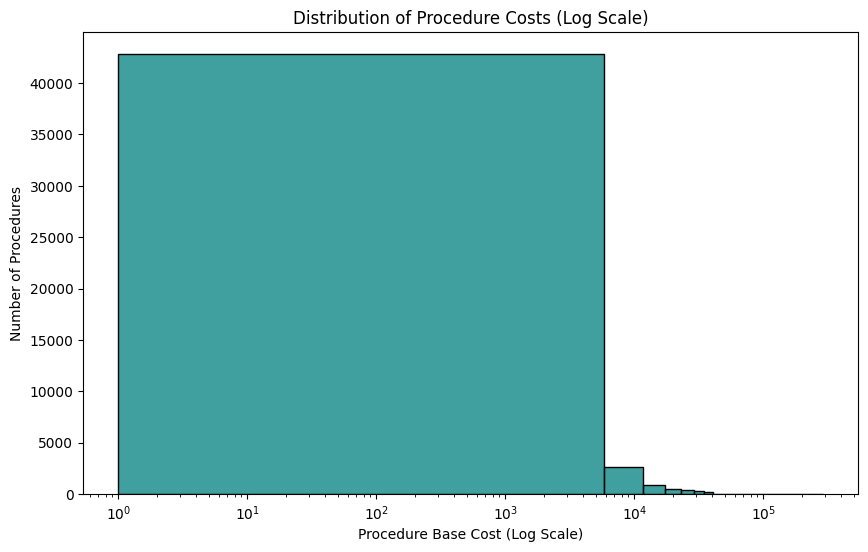

In [0]:
 # Task 2 – Point 4: Distribution of procedure costs

%pip install seaborn

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=procedure,
    x="BASE_COST",
    bins=50,
    color="teal"
)

plt.xscale("log")
plt.title("Distribution of Procedure Costs (Log Scale)")
plt.xlabel("Procedure Base Cost (Log Scale)")
plt.ylabel("Number of Procedures")

plt.show()

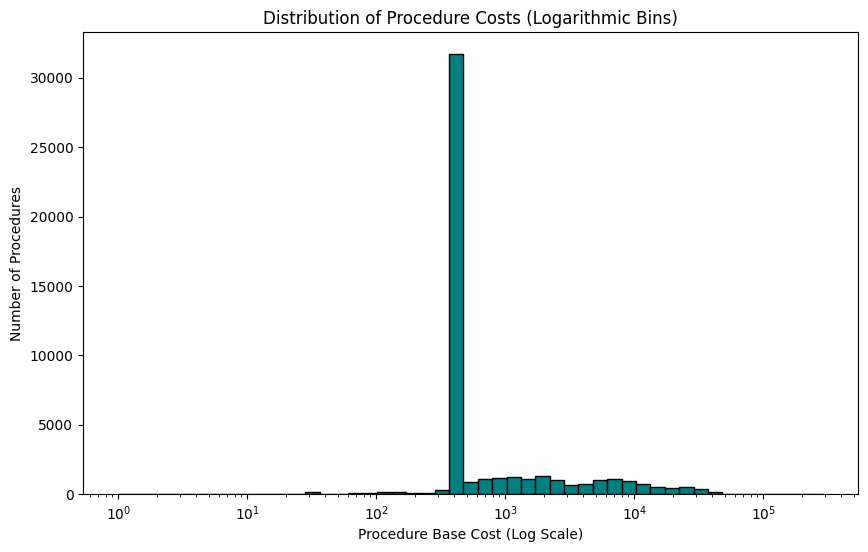

In [0]:
 # Task 2 – Point 4: Improved distribution of procedure costs

import numpy as np
import matplotlib.pyplot as plt

# Create logarithmically spaced bins
bins = np.logspace(
    np.log10(procedure["BASE_COST"].min()),
    np.log10(procedure["BASE_COST"].max()),
    50
)

plt.figure(figsize=(10, 6))

plt.hist(
    procedure["BASE_COST"],
    bins=bins,
    color="teal",
    edgecolor="black"
)

plt.xscale("log")
plt.title("Distribution of Procedure Costs (Logarithmic Bins)")
plt.xlabel("Procedure Base Cost (Log Scale)")
plt.ylabel("Number of Procedures")

plt.show()

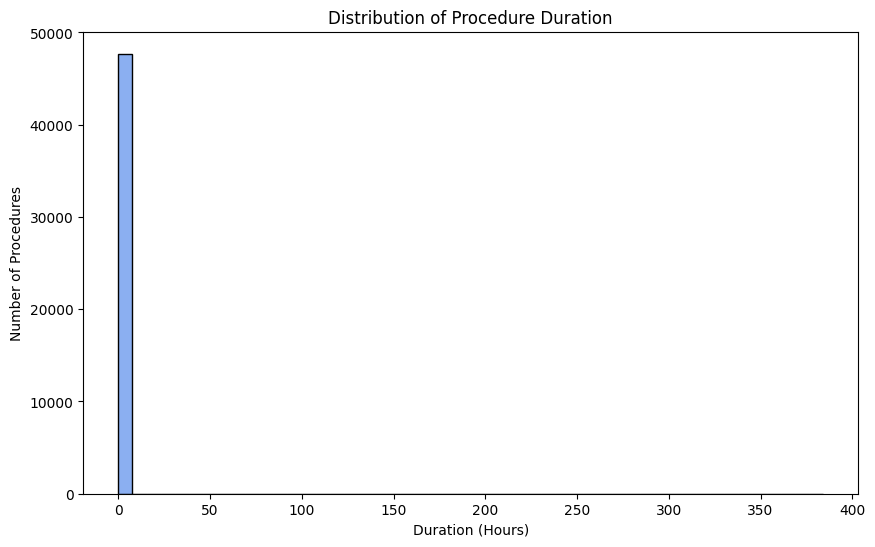

In [0]:
 # Task 2 – Point 4: Distribution of procedure duration

plt.figure(figsize=(10, 6))

sns.histplot(
    data=procedure,
    x="DURATION_HOURS",
    bins=50,
    color="cornflowerblue",
    edgecolor="black"
)

plt.title("Distribution of Procedure Duration")
plt.xlabel("Duration (Hours)")
plt.ylabel("Number of Procedures")

plt.show()

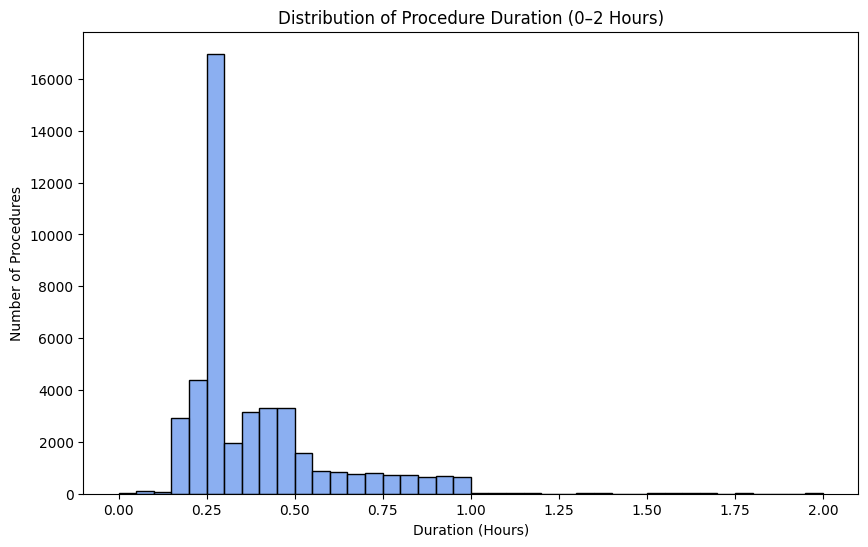

In [0]:
 # Task 2 – Point 4: Zoomed distribution of procedure duration

plt.figure(figsize=(10, 6))

sns.histplot(
    data=procedure[procedure["DURATION_HOURS"] <= 2],
    x="DURATION_HOURS",
    bins=40,
    color="cornflowerblue",
    edgecolor="black"
)

plt.title("Distribution of Procedure Duration (0–2 Hours)")
plt.xlabel("Duration (Hours)")
plt.ylabel("Number of Procedures")

plt.show()

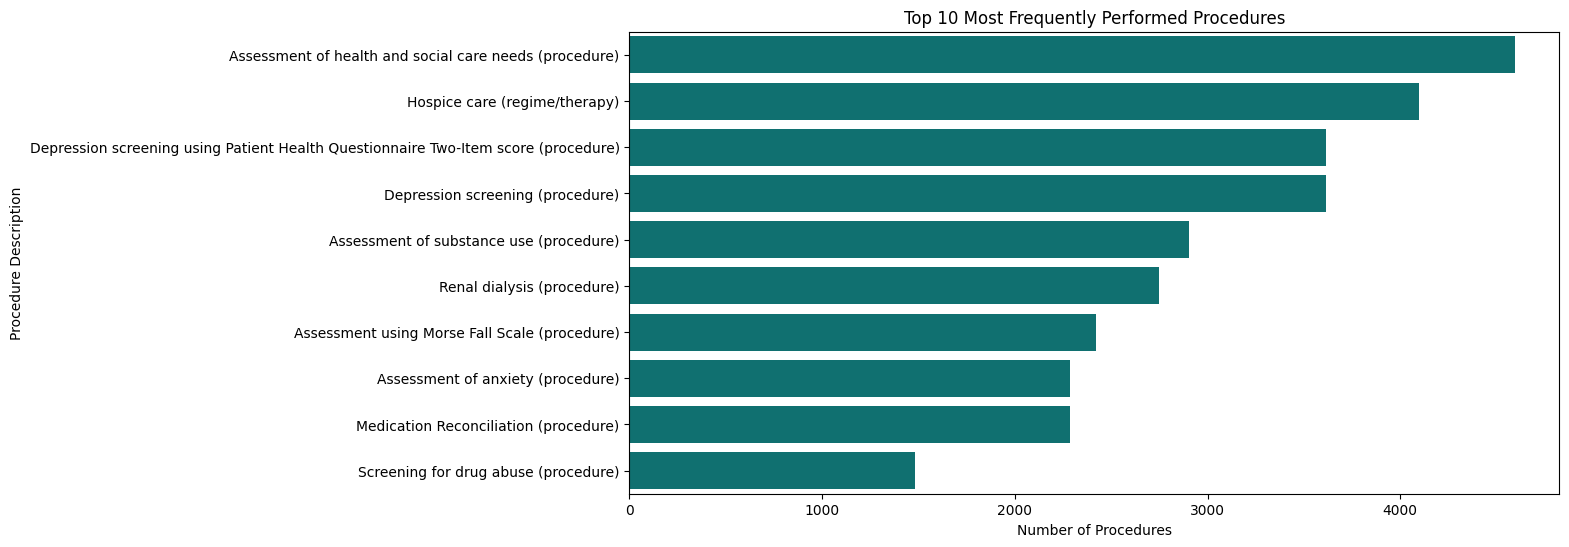

In [0]:
 # Task 2 – Point 4: Top 10 most frequent procedures

top_procedures = procedure["DESCRIPTION"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_procedures.values,
    y=top_procedures.index,
    color="teal"
)

plt.title("Top 10 Most Frequently Performed Procedures")
plt.xlabel("Number of Procedures")
plt.ylabel("Procedure Description")

plt.show()

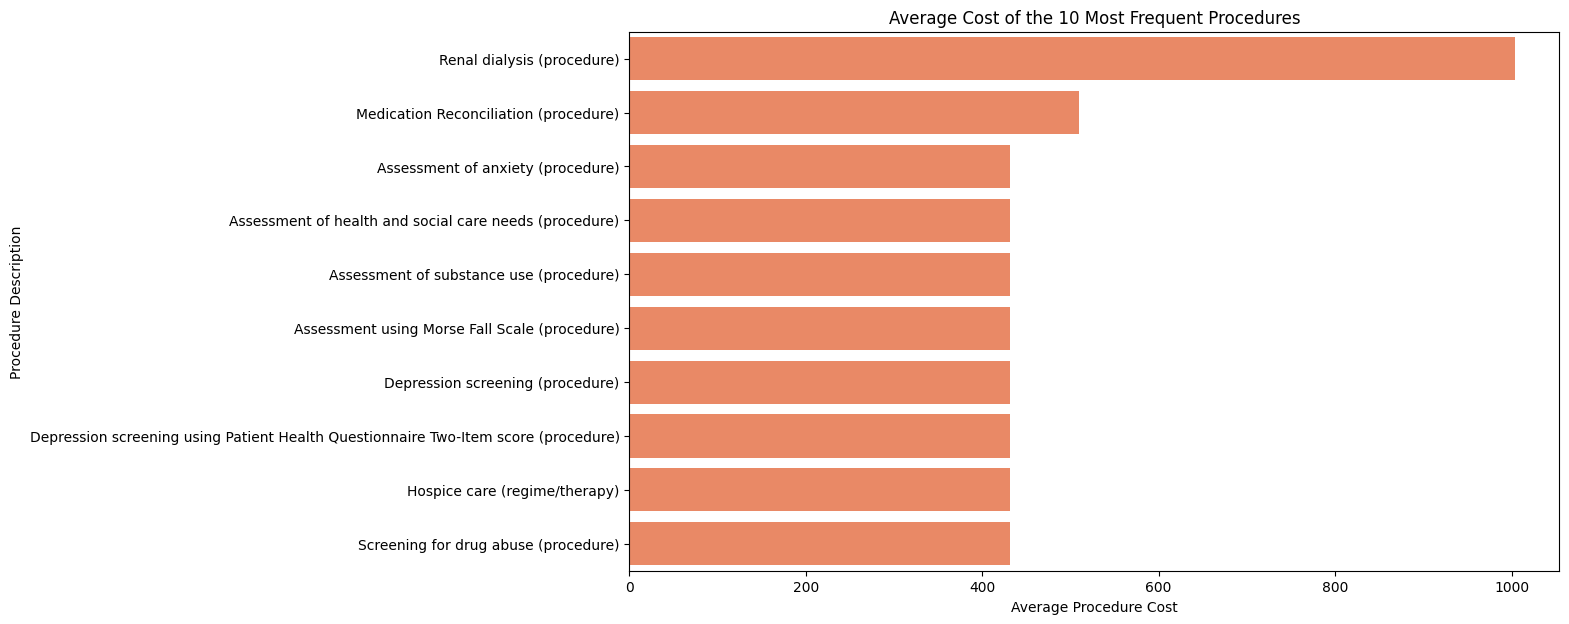

In [0]:
 # Task 2 – Point 4: Average cost of the top 10 frequent procedures

# Get the 10 most frequent procedure descriptions
top_10_names = procedure["DESCRIPTION"].value_counts().head(10).index

# Calculate average cost for these procedures
top_10_costs = (
    procedure[procedure["DESCRIPTION"].isin(top_10_names)]
    .groupby("DESCRIPTION")["BASE_COST"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_10_costs.values,
    y=top_10_costs.index,
    color="coral"
)

plt.title("Average Cost of the 10 Most Frequent Procedures")
plt.xlabel("Average Procedure Cost")
plt.ylabel("Procedure Description")

plt.show()

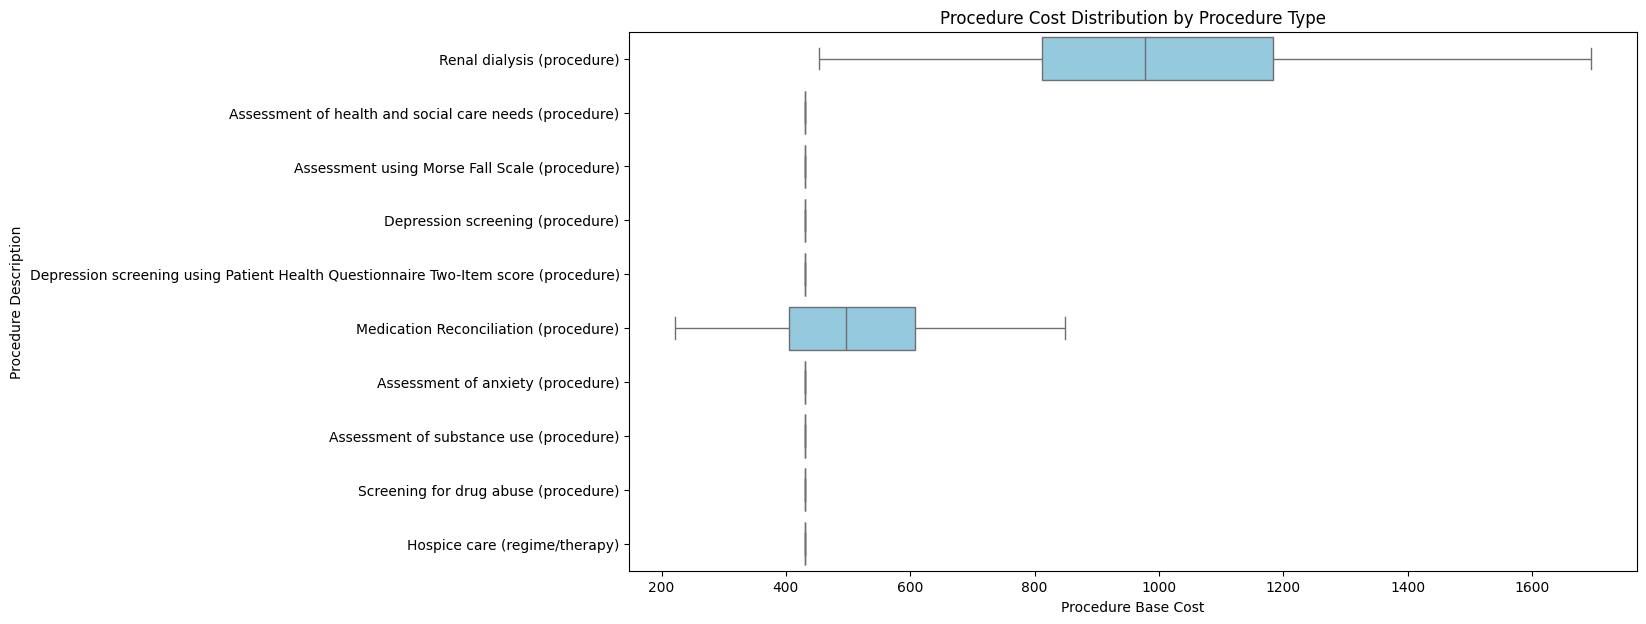

In [0]:
 # Task 2 – Point 4: Procedure cost distribution by procedure type

top_10_names = procedure["DESCRIPTION"].value_counts().head(10).index

top_10_data = procedure[
    procedure["DESCRIPTION"].isin(top_10_names)
]

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=top_10_data,
    x="BASE_COST",
    y="DESCRIPTION",
    color="skyblue"
)

plt.title("Procedure Cost Distribution by Procedure Type")
plt.xlabel("Procedure Base Cost")
plt.ylabel("Procedure Description")

plt.show()

In [0]:
 # Task 3 – Hypothesis 1: Spearman correlation test

from scipy.stats import spearmanr

# Test the relationship between procedure cost and duration
spearman_stat, p_value = spearmanr(
    procedure["BASE_COST"],
    procedure["DURATION_HOURS"]
)

print("Spearman correlation:", spearman_stat)
print("P-value:", p_value)

# Interpret the statistical significance
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("There is a statistically significant relationship.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a statistically significant relationship.")

Spearman correlation: -0.02178363697367955
P-value: 1.954160736086533e-06
Reject the null hypothesis.
There is a statistically significant relationship.


In [0]:
 # Task 3 – Hypothesis 2, Point 1: Select procedure types

top_5_procedures = procedure["DESCRIPTION"].value_counts().head(5)

print(top_5_procedures)

DESCRIPTION
Assessment of health and social care needs (procedure)                                4596
Hospice care (regime/therapy)                                                         4098
Depression screening using Patient Health Questionnaire Two-Item score (procedure)    3614
Depression screening (procedure)                                                      3614
Assessment of substance use (procedure)                                               2906
Name: count, dtype: int64


In [0]:
 # Task 3 – Hypothesis 2, Point 2: Prepare cost groups

from scipy.stats import kruskal

# Get the five most frequent procedure types
top_5_procedure_names = procedure["DESCRIPTION"].value_counts().head(5).index

# Create a separate cost group for each procedure type
cost_groups = []

for name in top_5_procedure_names:
    costs = procedure.loc[
        procedure["DESCRIPTION"] == name,
        "BASE_COST"
    ]

    cost_groups.append(costs)

    print(name, ":", len(costs), "records")

Assessment of health and social care needs (procedure) : 4596 records
Hospice care (regime/therapy) : 4098 records
Depression screening using Patient Health Questionnaire Two-Item score (procedure) : 3614 records
Depression screening (procedure) : 3614 records
Assessment of substance use (procedure) : 2906 records


In [0]:
 # Task 3 – Hypothesis 2, Point 3: Kruskal-Wallis test

from scipy.stats import kruskal

# The five most frequent procedure types all have the same fixed
# cost (431), which makes the Kruskal-Wallis test undefined.
# Compare the five most frequent procedure types whose costs vary instead.
nunique_costs = procedure.groupby("DESCRIPTION")["BASE_COST"].nunique()
varying_types = nunique_costs[nunique_costs > 1].index
top_5_varying = (
    procedure[procedure["DESCRIPTION"].isin(varying_types)]
    ["DESCRIPTION"]
    .value_counts()
    .head(5)
    .index
)

# Create a separate cost group for each procedure type
cost_groups = [
    procedure.loc[procedure["DESCRIPTION"] == name, "BASE_COST"]
    for name in top_5_varying
]

for name, costs in zip(top_5_varying, cost_groups):
    print(name, ":", len(costs), "records")

# Perform the test on the five cost groups
h_statistic, p_value = kruskal(*cost_groups)

# Display the results
print("Kruskal-Wallis H-statistic:", h_statistic)
print("P-value:", p_value)

# Interpret the p-value
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("There is a statistically significant difference in procedure costs.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a significant difference in procedure costs.")

Renal dialysis (procedure) : 2746 records
Medication Reconciliation (procedure) : 2284 records
Electrical cardioversion : 1383 records
Evaluation of uterine fundal height : 1065 records
Auscultation of the fetal heart : 1065 records
Kruskal-Wallis H-statistic: 7745.85897280695
P-value: 0.0
Reject the null hypothesis.
There is a statistically significant difference in procedure costs.


In [0]:
 # Task 3 – Hypothesis 2, Point 3: Verify selected groups

print("Procedure types used in the test:")

for name in top_5_procedure_names:
    print(name)

print("\nNumber of cost groups:", len(cost_groups))

Procedure types used in the test:
Assessment of health and social care needs (procedure)
Hospice care (regime/therapy)
Depression screening using Patient Health Questionnaire Two-Item score (procedure)
Depression screening (procedure)
Assessment of substance use (procedure)

Number of cost groups: 5


Task 5
## 2. Data Preparation Approach

The procedures dataset was used for this investigation. It contained 47,701 records and nine columns, including procedure dates, patient identifiers, encounter identifiers, procedure descriptions, recorded costs and associated diagnosis information.

### 2.1 Data Inspection and Cleaning

The dataset was inspected to understand its structure, column names, data types and missing values. The START and STOP columns were converted into datetime format to support date and time calculations.

The dataset contained 36,945 missing values in both REASONCODE and REASONDESCRIPTION, representing approximately 77.45% of the records. These missing values were retained because the associated diagnosis information was not available for many procedures. No artificial values were inserted.

Duplicate records and invalid dates were also checked. No duplicate records or invalid dates were identified.

### 2.2 Feature Engineering

A new variable called DURATION_HOURS was created by calculating the difference between the STOP and START timestamps. The difference was converted from seconds into hours.

This variable allowed procedure durations to be examined alongside recorded procedure costs.

### 2.3 Outlier Detection

The Interquartile Range (IQR) method was used to identify potential outliers in BASE_COST and DURATION_HOURS.

Potential upper outliers were identified in both variables. These observations were retained because unusually high costs or long durations may represent genuine healthcare procedures. They were considered during interpretation rather than automatically removed.

### 2.4 Preparation for Statistical Analysis

The cleaned dataset was used to examine procedure frequencies, cost distributions and procedure durations. The five most frequently performed procedure types were selected for cost comparison.

The prepared data was also used to investigate the association between procedure duration and recorded procedure cost.

## 3. Exploratory Findings

### 3.1 Dataset Overview

The procedures dataset contained 47,701 records and nine columns. The initial exploratory analysis identified no duplicate records. However, 36,945 records (77.45%) contained missing values in both REASONCODE and REASONDESCRIPTION. These missing values indicate that associated diagnosis information was unavailable for a large proportion of procedures.

### 3.2 Procedure Duration

Procedure duration was calculated using the difference between the START and STOP timestamps. The average duration was approximately 0.554 hours, while the median was approximately 0.276 hours. The minimum recorded duration was zero hours, and the maximum was 384 hours.

The mean being higher than the median suggests a right-skewed distribution, where a smaller number of procedures had substantially longer recorded durations. The IQR method identified 5,133 potential upper outliers, representing approximately 10.76% of the records.

### 3.3 Procedure Costs

The average recorded BASE_COST was 2,212.06, compared with a median of 431. The minimum recorded cost was 1, while the maximum was 289,531.

The difference between the mean and median suggests a right-skewed cost distribution, with some procedures having considerably higher recorded costs. The IQR method identified 9,174 potential upper outliers, representing approximately 19.23% of the records.

These values were retained because unusually high costs may reflect genuine differences in procedure types or resource requirements. The currency or unit of the recorded costs was not confirmed.

### 3.4 Most Frequently Performed Procedures

The five most frequent procedure types identified were:

1. Assessment of health and social care needs: 4,596 records.
2. Hospice care: 4,098 records.
3. Depression screening using PHQ-2: 3,614 records.
4. Depression screening: 3,614 records.
5. Assessment of substance use: 2,906 records.

These five procedure types were selected for further investigation to examine whether their recorded cost distributions differed.

## 4. Hypotheses and Statistical Methods

Two hypotheses were investigated to examine the relationship between procedure duration and cost, and differences in costs across frequently performed procedure types.

### 4.1 Hypothesis 1: Association Between Procedure Duration and Cost

The first hypothesis investigated whether procedure duration was associated with recorded procedure cost.

**Null hypothesis (H₀):** There is no significant monotonic relationship between procedure duration and procedure cost.

**Alternative hypothesis (H₁):** There is a significant monotonic relationship between procedure duration and procedure cost.

The variables used were DURATION_HOURS and BASE_COST.

Spearman rank correlation was selected because both variables showed skewed distributions and potential outliers. This non-parametric method measures the strength and direction of a monotonic relationship without requiring normally distributed variables.

The test produced a Spearman correlation coefficient of -0.02178 and a p-value of approximately 0.000001954. The result indicates a statistically significant but extremely weak negative association.

### 4.2 Hypothesis 2: Differences in Costs Across Procedure Types

The second hypothesis investigated whether recorded procedure costs differed across the five most frequently performed procedures.

**Null hypothesis (H₀):** The cost distributions are the same across the five procedure groups.

**Alternative hypothesis (H₁):** At least one procedure group has a different cost distribution.

The variables used were DESCRIPTION and BASE_COST.

The Kruskal–Wallis H-test was selected because it allows comparison of cost distributions across more than two independent groups without requiring normally distributed data.

The test produced an H-statistic of 7745.85897 and a p-value below 0.001. This provides strong statistical evidence that the cost distributions are not all the same across the five procedure groups.

The test does not identify which specific procedure groups differ. Further post-hoc analysis would be required to establish the individual group differences.

### 4.3 Statistical Method Selection

The statistical methods were selected according to the research questions, variable types and characteristics of the data. Non-parametric methods were preferred because the cost and duration variables were skewed and contained potential outliers.

The findings were interpreted using both statistical significance and practical significance. This distinction is important because a statistically significant result does not necessarily represent a meaningful or strong relationship.